# NANA · Preprocesado de la foto de una receta antes del OCR

**Materia:** Modelado y Procesamiento de Imágenes · **Proyecto:** NANA (Grupo 501)

En la app, la familia toma una foto de la receta y NANA la lee **dentro del celular** (OCR de Google ML Kit).
Antes del OCR la foto pasa por 5 pasos (`lib/core/preprocesar_foto.dart`):

1. Enderezar según la orientación de la cámara (EXIF).
2. Reducir a 1600 px de ancho.
3. Escala de grises.
4. **Corregir la luz:** estimar el fondo con un cierre morfológico (dilatar y luego erosionar borra la letra
   y deja solo el papel con su luz y sus sombras) y dividir la foto entre ese fondo.
5. Estirar el contraste (percentiles 2 % y 98 % del histograma).

**Cómo se eligieron:** la primera versión de la app usaba «contraste + suavizado». Este notebook mostró que
eso *empeoraba* la foto (sección 5), así que se cambió por la corrección de luz, que fue la mejor de todas.

Aquí se reproducen los pasos con OpenCV sobre una receta **sintética** con problemas de una foto real
(luz despareja, sombra, ruido, giro) y se comparan contra otras opciones (Otsu, umbral adaptativo).

**Cómo se mide:** como la receta es sintética, sabemos exactamente qué píxeles son letra. Se mide la
**separación entre letra y fondo** (razón de Fisher: diferencia de medias entre la suma de varianzas). Mientras más alta, más fácil para el OCR.
El OCR real se mide aparte en el celular con fotos de recetas reales (sección 6).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

np.random.seed(7)
plt.rcParams['figure.dpi'] = 110

## 1. Una receta sintética (y la máscara de dónde está el texto)

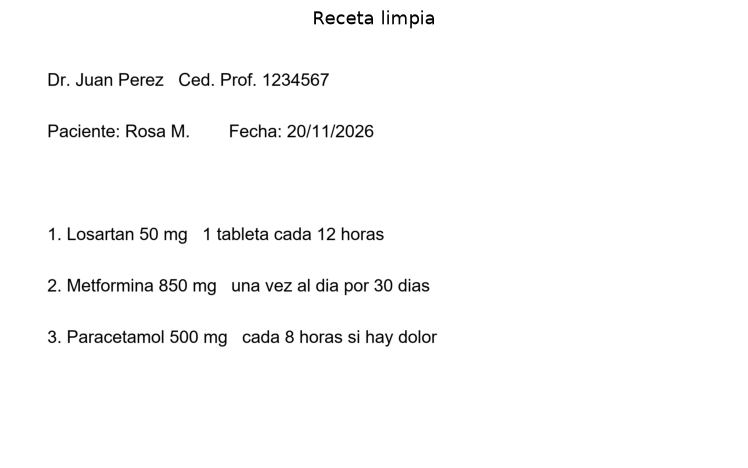

In [2]:
LINEAS = [
    'Dr. Juan Perez   Ced. Prof. 1234567',
    'Paciente: Rosa M.        Fecha: 20/11/2026',
    '',
    '1. Losartan 50 mg   1 tableta cada 12 horas',
    '2. Metformina 850 mg   una vez al dia por 30 dias',
    '3. Paracetamol 500 mg   cada 8 horas si hay dolor',
]

def fuente(tam):
    for nombre in ['arial.ttf', 'DejaVuSans.ttf']:
        try:
            return ImageFont.truetype(nombre, tam)
        except OSError:
            pass
    return ImageFont.load_default()

def receta_limpia(ancho=2400, alto=1400):
    papel = Image.new('L', (ancho, alto), 245)
    mascara = Image.new('L', (ancho, alto), 0)
    d, m = ImageDraw.Draw(papel), ImageDraw.Draw(mascara)
    f = fuente(58)
    for i, t in enumerate(LINEAS):
        y = 120 + i * 170
        d.text((120, y), t, fill=30, font=f)
        m.text((120, y), t, fill=255, font=f)
    return np.array(papel), np.array(mascara) > 0

limpia, texto = receta_limpia()
plt.figure(figsize=(9, 5)); plt.imshow(limpia, cmap='gray'); plt.axis('off'); plt.title('Receta limpia');

## 2. La foto como la toma un celular: color cálido, luz despareja, sombra, ruido y un poco girada

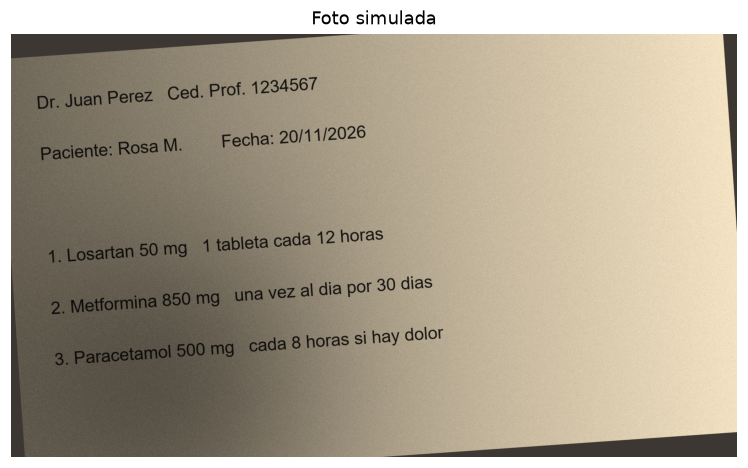

In [3]:
def como_foto(gris, mascara, angulo=4):
    alto, ancho = gris.shape
    yy, xx = np.mgrid[0:alto, 0:ancho]
    luz = 0.45 + 0.55 * (xx / ancho)                      # foco a la derecha
    sombra = 1 - 0.35 * np.exp(-((xx - 500) ** 2 + (yy - 1100) ** 2) / (2 * 380 ** 2))  # mano
    g = gris.astype(float) * luz * sombra
    g += np.random.normal(0, 9, g.shape)                   # ruido del sensor
    color = np.dstack([g * 1.0, g * 0.93, g * 0.80])      # papel amarillento
    color = np.clip(color, 0, 255).astype(np.uint8)
    giro = cv2.getRotationMatrix2D((ancho / 2, alto / 2), angulo, 1)
    foto = cv2.warpAffine(color, giro, (ancho, alto), borderValue=(60, 55, 50))
    mascara_g = cv2.warpAffine(mascara.astype(np.uint8), giro, (ancho, alto)) > 0
    return foto, mascara_g

foto, texto_g = como_foto(limpia, texto)
plt.figure(figsize=(9, 5)); plt.imshow(foto); plt.axis('off'); plt.title('Foto simulada');

## 3. Los mismos pasos que la app

El giro por EXIF (paso 1) lo resuelve la cámara; un giro de la mano, como estos 4°, ML Kit lo tolera.
Aquí se aplican los pasos 2 a 5.

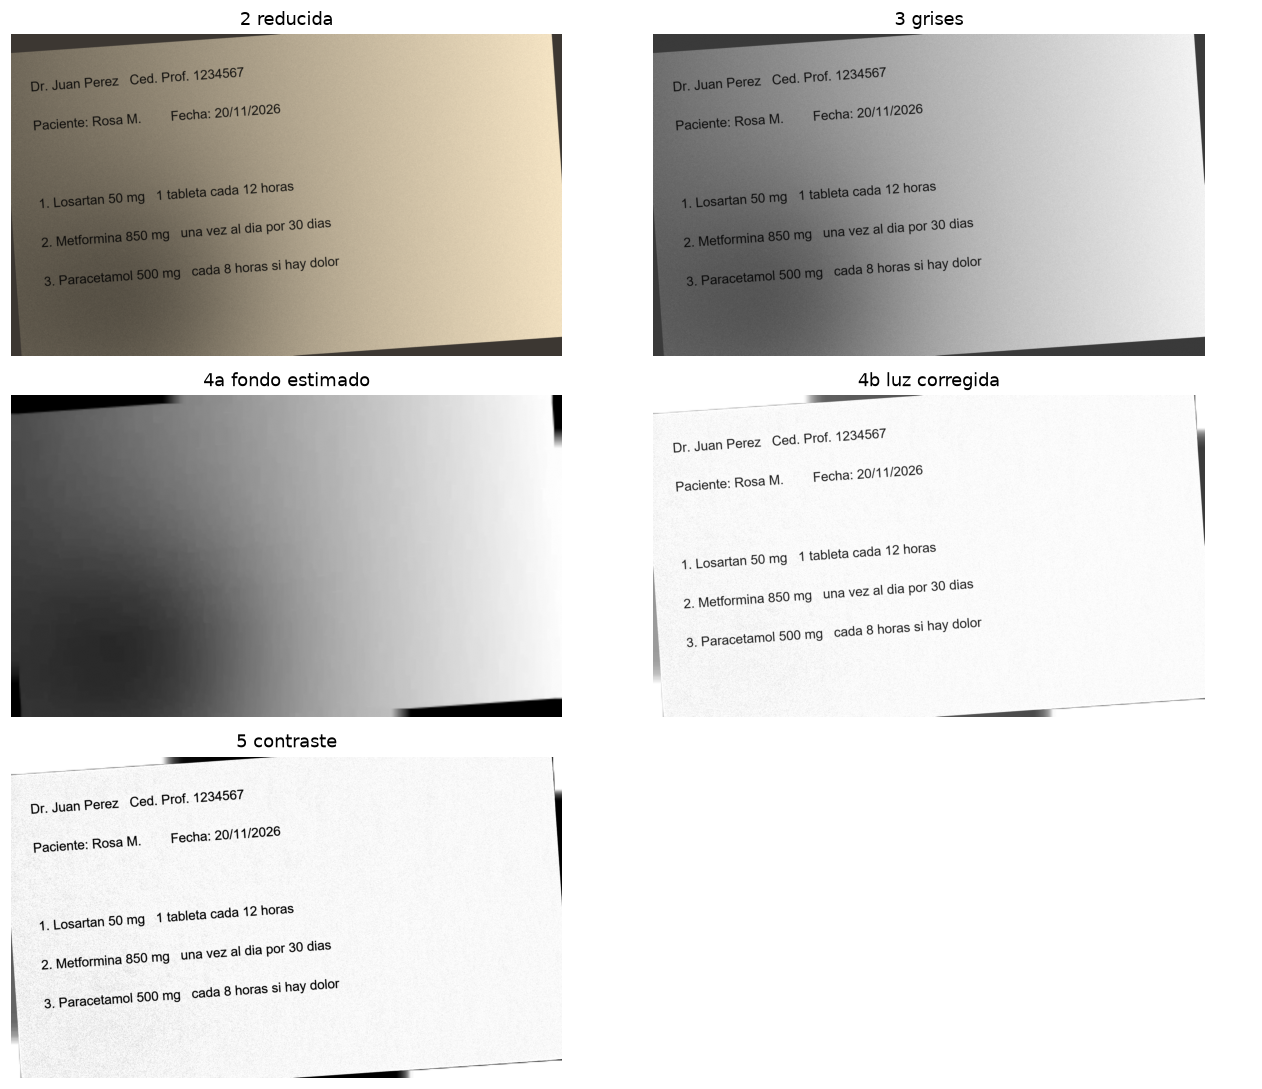

In [4]:
def reducir(img, ancho_max=1600):
    alto, ancho = img.shape[:2]
    if ancho <= ancho_max:
        return img
    return cv2.resize(img, (ancho_max, round(alto * ancho_max / ancho)), interpolation=cv2.INTER_AREA)

def estirar_contraste(gris, recorte=0.02):
    bajo, alto = np.percentile(gris, [recorte * 100, (1 - recorte) * 100])
    if alto - bajo < 10:
        return gris
    return np.clip((gris.astype(float) - bajo) * 255 / (alto - bajo), 0, 255).astype(np.uint8)

def corregir_luz(gris, chico=400, ventana=11):
    # Igual que corregirLuz() en Dart: el fondo se calcula en chiquito (rápido) y se agranda.
    alto, ancho = gris.shape
    mini = cv2.resize(gris, (chico, round(alto * chico / ancho)), interpolation=cv2.INTER_AREA)
    cuadro = np.ones((ventana, ventana), np.uint8)
    fondo = cv2.erode(cv2.dilate(mini, cuadro), cuadro)          # cierre morfológico
    fondo = cv2.resize(fondo, (ancho, alto), interpolation=cv2.INTER_LINEAR)
    return np.clip(gris.astype(float) / np.maximum(fondo, 1) * 255, 0, 255).astype(np.uint8), fondo

def como_la_app(foto):
    paso = {}
    paso['2 reducida'] = r = reducir(foto)
    paso['3 grises'] = g = cv2.cvtColor(r, cv2.COLOR_RGB2GRAY)
    l, paso['4a fondo estimado'] = corregir_luz(g)
    paso['4b luz corregida'] = l
    paso['5 contraste'] = estirar_contraste(l)
    return paso

pasos = como_la_app(foto)
mask = reducir(texto_g.astype(np.uint8) * 255) > 127

fig, ejes = plt.subplots(3, 2, figsize=(12, 10))
for eje, (nombre, im) in zip(ejes.flat, pasos.items()):
    eje.imshow(im, cmap=None if im.ndim == 3 else 'gray'); eje.set_title(nombre); eje.axis('off')
ejes.flat[-1].axis('off')
plt.tight_layout()

## 4. Histogramas: qué hace «estirar el contraste»

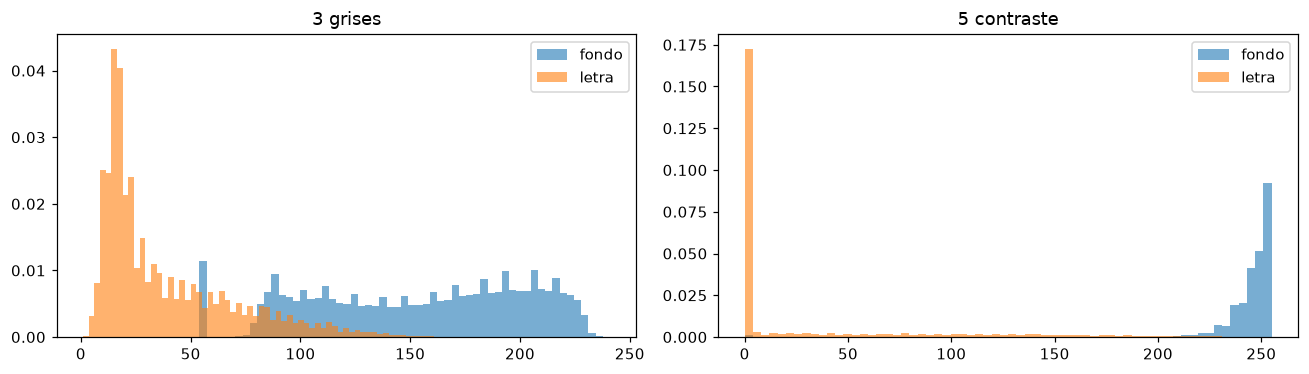

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
for eje, nombre in zip(ejes, ['3 grises', '5 contraste']):
    im = pasos[nombre]
    eje.hist(im[~mask].ravel(), bins=64, alpha=.6, label='fondo', density=True)
    eje.hist(im[mask].ravel(), bins=64, alpha=.6, label='letra', density=True)
    eje.set_title(nombre); eje.legend()
plt.tight_layout()

## 5. Comparación de opciones

Se mide la separación letra/fondo (razón de Fisher) de cada versión. Incluye la primera versión de la app
(«contraste + suavizado») para mostrar por qué se cambió.

foto en grises (sin nada)      separación letra/fondo =   4.13
1.ª versión: contraste + suavizado separación letra/fondo =   2.86
Otsu (global)                  separación letra/fondo =   1.28
umbral adaptativo              separación letra/fondo =   5.89
APP: luz + contraste           separación letra/fondo =  12.13


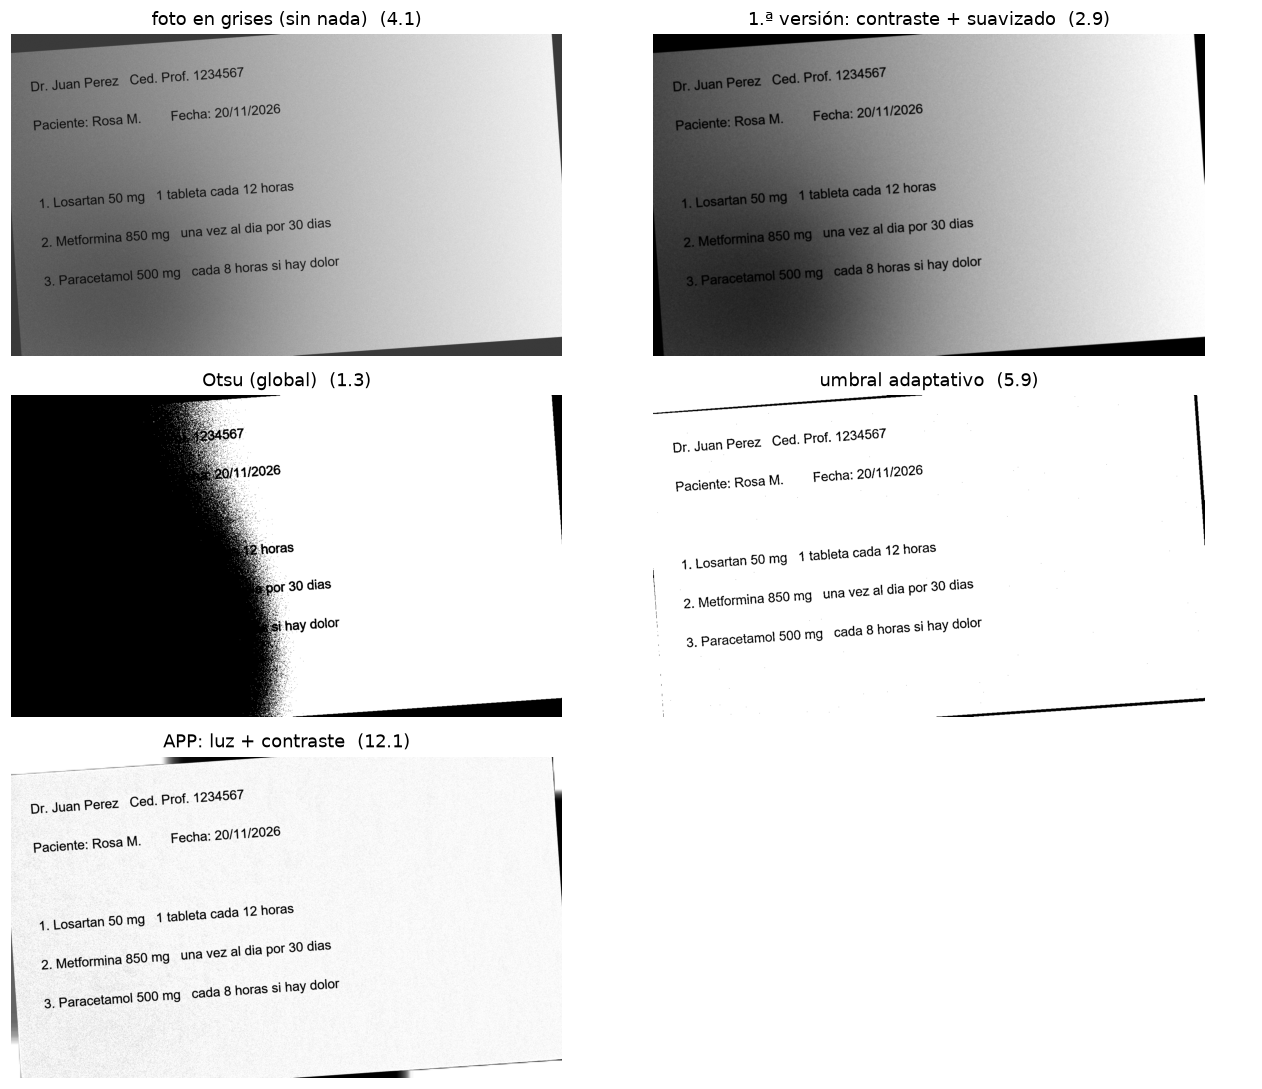

In [6]:
def fisher(im, mascara):
    a, b = im[mascara].astype(float), im[~mascara].astype(float)
    return abs(a.mean() - b.mean()) ** 2 / (a.var() + b.var() + 1e-9)

gris = pasos['3 grises']
_, otsu = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptativo = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)

primera = cv2.GaussianBlur(estirar_contraste(gris), (3, 3), 0)
versiones = {
    'foto en grises (sin nada)': gris,
    '1.ª versión: contraste + suavizado': primera,
    'Otsu (global)': otsu,
    'umbral adaptativo': adaptativo,
    'APP: luz + contraste': pasos['5 contraste'],
}
for nombre, im in versiones.items():
    print(f'{nombre:<30} separación letra/fondo = {fisher(im, mask):6.2f}')

fig, ejes = plt.subplots(3, 2, figsize=(12, 10))
for eje, (nombre, im) in zip(ejes.flat, versiones.items()):
    eje.imshow(im, cmap='gray'); eje.set_title(f'{nombre}  ({fisher(im, mask):.1f})'); eje.axis('off')
ejes.flat[-1].axis('off')
plt.tight_layout()

**Qué se aprendió:**
- Estirar el contraste *solo* no sirve con luz despareja: el lado oscuro y el claro se estiran juntos, y el
  suavizado borra el borde de letras delgadas. La primera versión de la app quedó **peor** que no hacer nada.
- Otsu (un solo umbral para toda la hoja) pierde la parte en sombra.
- El umbral adaptativo ayuda, pero deja ruido en el papel.
- **Corregir la luz** (dividir entre el fondo) quita la sombra y el degradado; después el contraste ya separa bien.
  Fue la mejor y es la que usa la app.

> Nota honesta: la separación es una medida indirecta y la receta es sintética. La prueba que cuenta es el OCR
> real en el celular (sección 6).

## 5b. ¿Qué tan grande debe ser el cuadro del cierre?

In [7]:
for v in (5, 9, 11, 15, 21, 31):
    l, _ = corregir_luz(gris, ventana=v)
    print(f'ventana {v:>2} px (a 400 px de ancho) -> separación {fisher(estirar_contraste(l), mask):5.2f}')

ventana  5 px (a 400 px de ancho) -> separación 19.41
ventana  9 px (a 400 px de ancho) -> separación 13.59
ventana 11 px (a 400 px de ancho) -> separación 12.13
ventana 15 px (a 400 px de ancho) -> separación  9.65
ventana 21 px (a 400 px de ancho) -> separación  8.45


ventana 31 px (a 400 px de ancho) -> separación  7.28


En esta receta sintética los cuadros chicos salen mejor, porque sus letras son delgadas (≈1.5 px a 400 px de ancho). Pero el cuadro tiene que ser más grande que el trazo: con letra gruesa o en negritas, un cuadro de 5 px no borra la letra, la letra se cuela al «fondo» y al dividir se deslava. La app usa **11** como margen para letra gruesa; hay que confirmarlo con fotos reales (sección 6) y bajarlo si las recetas reales leen mejor con 9.

## 6. Prueba con recetas reales (en el celular)

En esta PC no hay motor de OCR instalado, así que el OCR real se mide en el celular con ML Kit:

1. Tomar 5 fotos de recetas reales (con permiso; tapar nombres) con distinta luz.
2. En NANA → Medicinas → **Leer una receta con la cámara**.
3. Anotar por foto: medicinas que tenía la receta, cuántas leyó bien NANA, cuántas hubo que corregir en «¿Está bien así?».

| Foto | Luz | Medicinas en la receta | Leídas bien | Corregidas | Notas |
|---|---|---|---|---|---|
| 1 | | | | | |
| 2 | | | | | |
| 3 | | | | | |
| 4 | | | | | |
| 5 | | | | | |

Para comparar sin preprocesado: en `lib/core/preprocesar_foto.dart`, `PasosPreprocesado(luz: false, contraste: false)`.